# 15 · Grid congestion management with flexibility: smart charging for the DSO
**Level 6 · System integration** &nbsp;|&nbsp; Course link: *Module 6 – grid congestion management: flexibility,
the role of the DSO, spatial flexibility*

The capstone (notebook 08) showed that uncontrolled EV charging overloads a cable and the transformer of a rural grid.
Building new cables takes years; **flexibility** is available now: most cars are parked for 12 hours but need only 2.
This notebook compares four ways to charge 92 cars on a winter evening:

| strategy | who decides | knows the grid? |
|---|---|---|
| A. plug-and-charge | each driver | no |
| B. price-optimal smart charging | each car, cheapest hours | no |
| C. blanket dimming of all chargers to 4.2 kW in the evening (rule, cf. German §14a EnWG) | DSO rule | crudely |
| D. grid-aware optimal charging | DSO + aggregator (LP) | yes |

Every schedule is checked with a full AC power flow every 15 minutes.

In [1]:
import warnings, json
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import networkx as nx, pandapower.topology as top
import scipy.sparse as sp
from scipy.optimize import linprog
from energy_ai import simbench_grid, fast_pf, day_ahead_price, style
style()
rng = np.random.default_rng(3)

CODE = "1-LV-rural2--2-sw"
net, prof = simbench_grid(CODE)
net.storage["in_service"] = False
steps = pd.date_range("2016-01-13 12:00", periods=96, freq="15min")       # winter Wednesday noon -> Thursday noon
base_p = prof[("load", "p_mw")].loc[steps].values * 1000                  # kW, households + heat pumps + businesses
base_q = prof[("load", "q_mvar")].loc[steps].values * 1000
pv = prof[("sgen", "p_mw")].loc[steps].values * 1000
price = day_ahead_price("DE_LU", "2019-01-16", "2019-01-18").tz_convert("Europe/Berlin").tz_localize(None)
price = price.loc["2019-01-16 12:00":"2019-01-17 11:00"].values.repeat(4) / 1000 + 0.25    # €/kWh, same weekday
DT = 0.25                                                                  # h per step
print(f"{len(net.load)} loads, {len(net.line)} lines, transformer {1000 * net.trafo.sn_mva.iloc[0]:.0f} kVA | "
      f"base demand {base_p.sum(1).min():.0f}–{base_p.sum(1).max():.0f} kW")

118 loads, 95 lines, transformer 250 kVA | base demand 13–82 kW


## 1. Charging sessions
Every household has one car: arrival around 18:00, departure around 07:30, energy need 6–20 kWh, 11 kW charger.

In [2]:
homes = np.where(net.load.profile.astype(str).str.startswith("H0"))[0]
t_of = lambda hours_after_noon: int(np.clip(round(hours_after_noon * 4), 0, 95))
arr = np.array([t_of(rng.normal(6.0, 1.5)) for _ in homes]); arr = np.clip(arr, t_of(3), t_of(11))
dep = np.array([t_of(rng.normal(19.5, 0.75)) for _ in homes]); dep = np.clip(dep, t_of(17.5), t_of(22))
need = np.minimum(rng.uniform(6, 20, len(homes)), 0.9 * 11 * (dep - arr) * DT)
PMAX = 11.0
n_ev = len(homes)
print(f"{n_ev} cars | total energy needed {need.sum():.0f} kWh | average plug-in time {((dep - arr) * DT).mean():.1f} h, "
      f"average charging time at 11 kW {(need / PMAX).mean():.1f} h")

92 cars | total energy needed 1259 kWh | average plug-in time 13.7 h, average charging time at 11 kW 1.2 h


## 2. The grid as a linear model: who is behind which cable?
In a radial grid the power through a cable equals the net demand of everything downstream of it. With the topology
matrix $D$ (cable × customer, 1 if the customer is behind the cable), the flows are simply $D\,(P_{base} + P_{EV} - P_{PV})$.
This is the radial version of the **PTDF** matrix used in transmission grids. Limits in kW come from the thermal
rating ($\sqrt3\,U\,I_{max}$) with a 10 % margin for reactive power and voltage drop.

In [3]:
g = top.create_nxgraph(net, respect_switches=True)
tbus = net.trafo.lv_bus.iloc[0]
tree = nx.bfs_tree(g, tbus)
def downstream(bus): return {bus} | nx.descendants(tree, bus)
lines = net.line[net.line.in_service].index
D_load = np.zeros((len(lines), len(net.load))); D_pv = np.zeros((len(lines), len(net.sgen)))
for r, li in enumerate(lines):
    a, b = net.line.from_bus[li], net.line.to_bus[li]
    child = b if b in tree.successors(a) else a
    below = downstream(child)
    D_load[r] = net.load.bus.isin(below).values; D_pv[r] = net.sgen.bus.isin(below).values
lim_line = 0.9 * np.sqrt(3) * 0.4 * net.line.max_i_ka.loc[lines].values * 1000           # kW
lim_trafo = 0.9 * net.trafo.sn_mva.iloc[0] * 1000
D_ev = D_load[:, homes]
print(f"topology matrix D: {D_load.shape[0]} cables × {D_load.shape[1]} customers")

topology matrix D: 95 cables × 118 customers


## 3. Four charging strategies

In [4]:
def plug_and_charge():
    P = np.zeros((96, n_ev))
    for i in range(n_ev):
        left = need[i]
        for t in range(arr[i], dep[i]):
            P[t, i] = min(PMAX, left / DT); left -= P[t, i] * DT
            if left <= 1e-9: break
    return P

def dimming_rule(p_cap=4.2, start=t_of(5), stop=t_of(11)):
    """Plug-and-charge, but the DSO caps every charger at p_cap kW between 17:00 and 23:00."""
    P = np.zeros((96, n_ev))
    for i in range(n_ev):
        left = need[i]
        for t in range(arr[i], dep[i]):
            cap = p_cap if start <= t < stop else PMAX
            P[t, i] = min(cap, left / DT); left -= P[t, i] * DT
            if left <= 1e-9: break
    return P

def optimal(grid_aware):
    """LP over all cars: minimise charging cost; optionally keep every cable and the transformer within limits."""
    nv = 96 * n_ev                                  # variable (t, i) at position t * n_ev + i
    ub = np.zeros((96, n_ev))
    for i in range(n_ev): ub[arr[i]:dep[i], i] = PMAX
    A_eq = sp.kron(sp.csr_matrix(np.ones((1, 96))), sp.eye(n_ev)) * DT          # sum_t P[t,i]·Δt = need_i
    c = (np.repeat(price, n_ev) + 1e-5 * np.tile(np.arange(n_ev), 96)) * DT       # tiny tie-breaker between cars
    A_ub, b_ub = None, None
    if grid_aware:
        base_line = base_p @ D_load.T - pv @ D_pv.T                             # (96, cables)
        A_line = sp.kron(sp.eye(96), sp.csr_matrix(D_ev))
        A_tr = sp.kron(sp.eye(96), sp.csr_matrix(np.ones((1, n_ev))))
        A_ub = sp.vstack([A_line, A_tr]).tocsr()
        b_ub = np.r_[(lim_line[None, :] - base_line).ravel(), lim_trafo - (base_p.sum(1) - pv.sum(1))]
    res = linprog(c, A_ub=A_ub, b_ub=b_ub, A_eq=A_eq, b_eq=need, bounds=np.c_[np.zeros(nv), ub.ravel()], method="highs")
    assert res.status == 0, res.message
    return res.x.reshape(96, n_ev)

schedules = {"A. plug-and-charge": plug_and_charge(), "B. price-optimal (grid-blind)": optimal(False),
             "C. dimming rule 4.2 kW, 17–23 h": dimming_rule(), "D. grid-aware optimal": optimal(True)}

## 4. Verification with AC power flow

,max cable loading [%],cable-overload hours,max transformer loading [%],min voltage [pu],charging cost [€],energy not delivered [kWh]
strategy,,,,,,
A. plug-and-charge,120.09,0.75,160.28,0.92,377.94,0.0
B. price-optimal (grid-blind),337.38,1.50,511.94,0.67,343.82,0.0
"C. dimming rule 4.2 kW, 17–23 h",80.58,0.00,130.40,0.95,373.54,0.0
D. grid-aware optimal,92.62,0.00,92.14,0.95,346.76,0.0


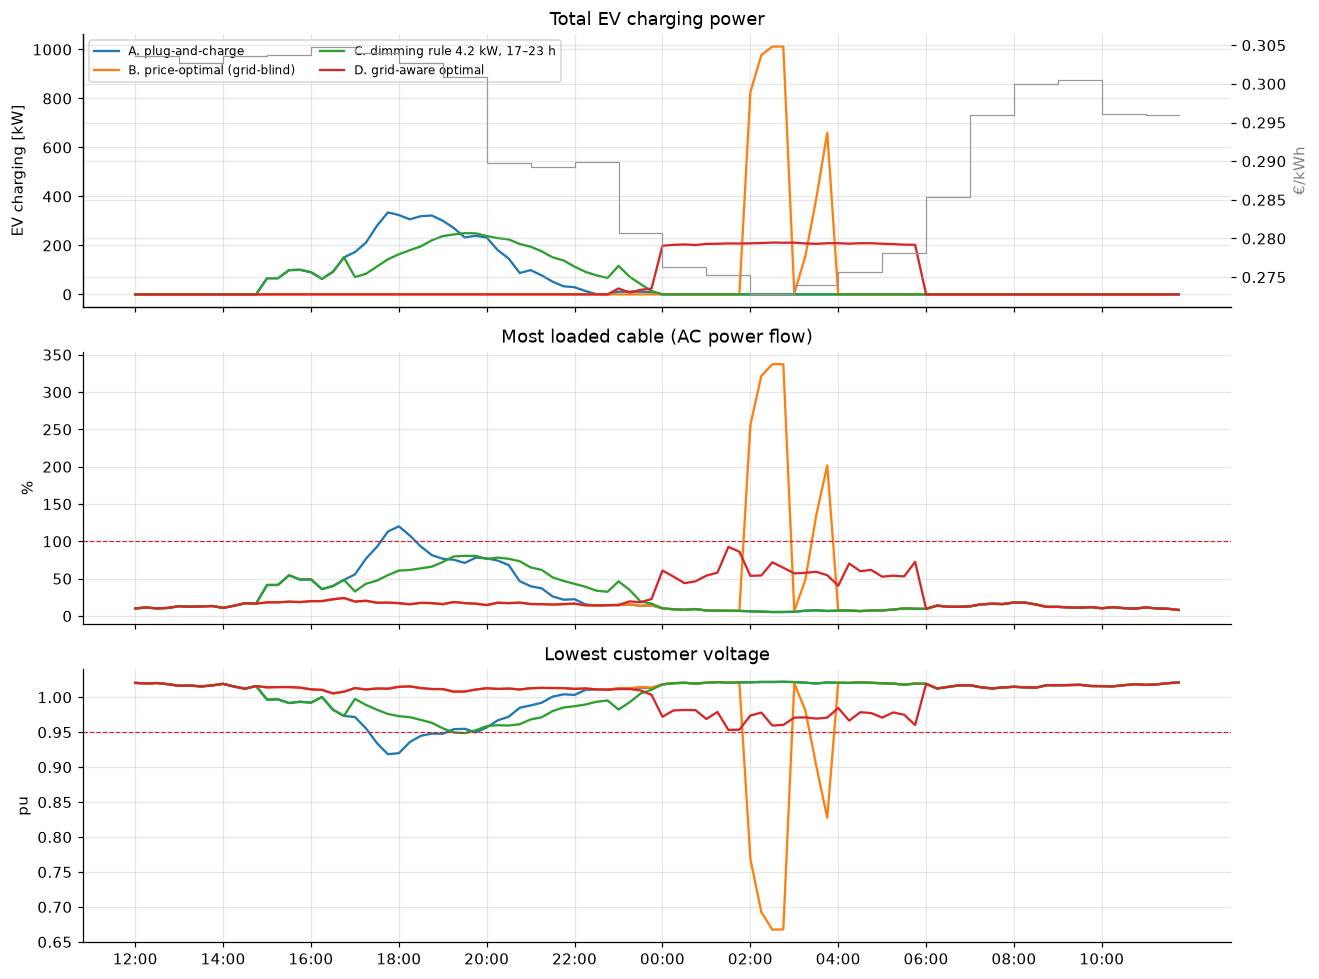

In [5]:
def ac_check(P_ev):
    ld, vmin, trafo, delivered = [], [], [], P_ev.sum(0) * DT
    for t in range(96):
        p = base_p[t].copy(); p[homes] += P_ev[t]
        net.load["p_mw"], net.load["q_mvar"], net.sgen["p_mw"] = p / 1000, base_q[t] / 1000, pv[t] / 1000
        fast_pf(net)
        ld.append(net.res_line.loading_percent.values.copy()); vmin.append(net.res_bus.vm_pu.min()); trafo.append(net.res_trafo.loading_percent.iloc[0])
    return np.array(ld), np.array(vmin), np.array(trafo), delivered

rows, ac = [], {}
for name, P in schedules.items():
    ld, vmin, tr, delivered = ac_check(P); ac[name] = (ld, vmin, tr)
    rows.append({"strategy": name, "max cable loading [%]": ld.max(), "cable-overload hours": (ld.max(1) > 100).sum() * DT,
                 "max transformer loading [%]": tr.max(), "min voltage [pu]": vmin.min(),
                 "charging cost [€]": (P.sum(1) * price).sum() * DT, "energy not delivered [kWh]": max(0.0, (need - delivered).sum())})
table = pd.DataFrame(rows).set_index("strategy")
display(table.round(2))

hours = steps.strftime("%H:%M")
fig, ax = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for name, P in schedules.items():
    ax[0].plot(P.sum(1), label=name)
    ax[1].plot(ac[name][0].max(1), label=name)
    ax[2].plot(ac[name][1], label=name)
ax[0].set(ylabel="EV charging [kW]", title="Total EV charging power"); ax[0].legend(fontsize=8, ncol=2)
ax0b = ax[0].twinx(); ax0b.step(range(96), price, where="post", color="0.6", lw=0.8); ax0b.set_ylabel("€/kWh", color="0.5")
ax[1].axhline(100, color="tab:red", ls="--", lw=0.8); ax[1].set(ylabel="%", title="Most loaded cable (AC power flow)")
ax[2].axhline(0.95, color="tab:red", ls="--", lw=0.8); ax[2].set(ylabel="pu", title="Lowest customer voltage")
ax[2].set_xticks(range(0, 96, 8)); ax[2].set_xticklabels(hours[::8]); plt.tight_layout(); plt.show()

## 5. Spatial flexibility: location matters
In strategy D two kinds of constraint bind: the transformer (shared by **all** cars) and the feeder cables (shared only
by the cars on that feeder). Suppose the DSO replaces the transformer by a 630 kVA unit, so only cable limits remain.
How much must the cars on each feeder deviate from their cheapest (market) schedule B?

In [6]:
lim_trafo_250, sn_250 = lim_trafo, net.trafo.sn_mva.iloc[0]
lim_trafo = 0.9 * 630; net.trafo["sn_mva"] = 0.63
P_up = optimal(True); P_mkt = schedules["B. price-optimal (grid-blind)"]
ld_up, vmin_up, tr_up, _ = ac_check(P_up)
lim_trafo = lim_trafo_250; net.trafo["sn_mva"] = sn_250
shifted = np.abs(P_up - P_mkt).sum(0) * DT / 2                      # kWh per car moved to other hours by the DSO
print(f"AC check with a 630 kVA transformer: max cable {ld_up.max():.0f} %, transformer {tr_up.max():.0f} %, "
      f"min voltage {vmin_up.min():.3f} pu")

heads = [li for li in net.line.index if tbus in (net.line.from_bus[li], net.line.to_bus[li])]
feeders = []
for li in heads:
    r = list(lines).index(li); cars = D_ev[r] > 0
    feeders.append({"feeder head cable": f"line{li}", "cars on feeder": int(cars.sum()),
                    "head-cable loading, grid-blind B [%]": ac["B. price-optimal (grid-blind)"][0][:, net.line.index.get_loc(li)].max(),
                    "energy moved by the DSO per car [kWh]": shifted[cars].mean() if cars.any() else 0.0})
display(pd.DataFrame(feeders).set_index("feeder head cable").round(1))

AC check with a 630 kVA transformer: max cable 94 %, transformer 92 %, min voltage 0.939 pu


,cars on feeder,"head-cable loading, grid-blind B [%]",energy moved by the DSO per car [kWh]
feeder head cable,,,
line15,41,337.4,8.9
line41,16,108.0,4.0
line92,15,101.8,3.7
line93,20,137.0,4.0


The most congested feeder carries most of the burden. Note the voltage: with the transformer bottleneck removed, more
simultaneous charging pulls the lowest voltage to ≈ 0.94 pu. Our LP only has thermal limits; a full DSO model adds
voltage limits through linearised voltage sensitivities, in the same way as the cable matrix $D$.

## Key takeaways
* Uncontrolled charging overloads cables and depresses voltages at the evening peak.
* **Grid-blind smart charging can make congestion worse**: if every car reacts to the same price signal, they all
  charge in the same cheap hours ("herding"), creating a new, sharper peak.
* Blanket rules (dimming every charger) are simple but blunt: they restrict everyone, including cars on uncongested
  feeders, and they can still fail: here ~60 cars charging at 4.2 kW around 19:00 still overload the transformer.
* **Grid-aware optimisation** keeps every asset within limits for about 1 % extra charging cost.
* Flexibility has a **location**: a transformer limit needs flexibility from everyone, a cable limit only from the
  customers behind that cable, and the more congested the feeder, the more its customers must shift. This is the logic of local flexibility markets and DSO–aggregator coordination
  (notebooks 09 and 11 provide the optimisation tools).